# 01-OTA远程升级概述


## 1. 本课内容与资料

本篇对应视频 `01_OTA远程升级概述.mp4`，播放器显示时长约 **12 分 44 秒**，配套讲义为 `OTA远程升级.pdf` 第 **3—20 页**（按 PDF 物理页序号）。原课按“为什么要升级 → IAP、OTA、ISP 概念 → 应用与需求 → 学习路径 → 环境准备和基础工程验证 → 总结”展开。

资料来自[课程百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`，目录为 `9、嵌入式物联网OTA远程升级`。

本篇已读取覆盖到 `12:42.640` 的完整自动中文字幕，并对照讲义原图、视频中的代码和串口实操画面整理。字幕中的 `CAN`、`Ymodem`、`Bootloader` 等识别错误按课件和画面校正。代码摘自视频可见片段，未审阅 `Code.zip`，也未在本地开发板上验证；下文实验现象均为课堂演示结果。

本节先建立概念并运行普通示例工程。Flash 擦写、固件接收和 Bootloader 跳转的具体实现属于后续课程。


## 2. 为什么需要远程更新固件

固件是运行在设备上的程序。课程先设定一个已经交付产品的场景：上千台设备部署在全国各地，突然发现严重 bug，或者客户要求增加功能，需要把新程序更新到这些设备。

如果仍由工程师携带电脑和下载器，逐台到现场拆壳、接线、烧录，设备越多，时间和差旅成本越高。对于高空、深海、全封闭等难以接近的设备，拆机更新甚至很难实施。

于是，课程提出解决方向：**利用设备已有的通信接口接收新固件，再由设备完成程序更新。** 通信通道可以是一根通信线，也可以是无线网络，减少为更新程序而反复拆机的需要。

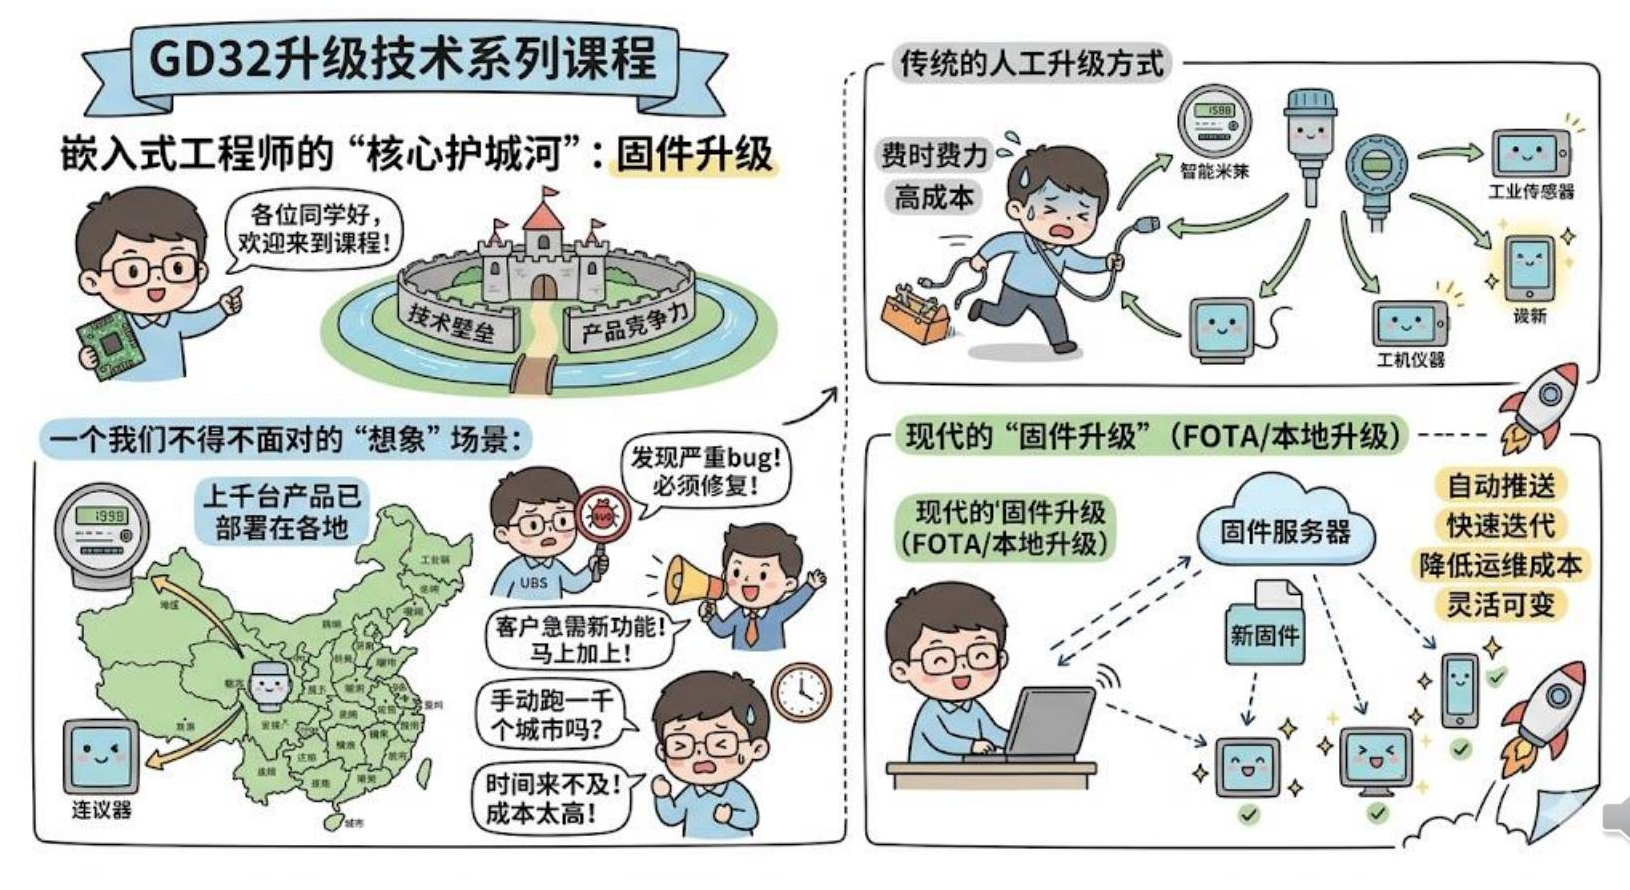

*讲义第 5 页：已经交付的设备仍然需要修复问题、增加功能，固件维护贯穿产品使用过程。*


## 3. IAP：让设备自己接收并更新程序

**IAP（In-Application Programming，应用内编程，也称在线应用编程）**，在本课中的含义是：单片机通过 UART、CAN 等通信接口接收新程序，再由设备中运行的软件将程序更新到自己的 Flash 中。

可以先按下面的顺序理解它：

1. 外部把新固件经通信接口发送给设备。
2. 设备上的升级程序接收固件。
3. 单片机自身执行 Flash 更新，使后续能运行新程序。

其中，UART 是串口通信接口，CAN 是常见的总线通信方式，Flash 是保存程序的非易失性存储器。**接收数据与更新 Flash 是两个环节**；本节只介绍它们的关系。

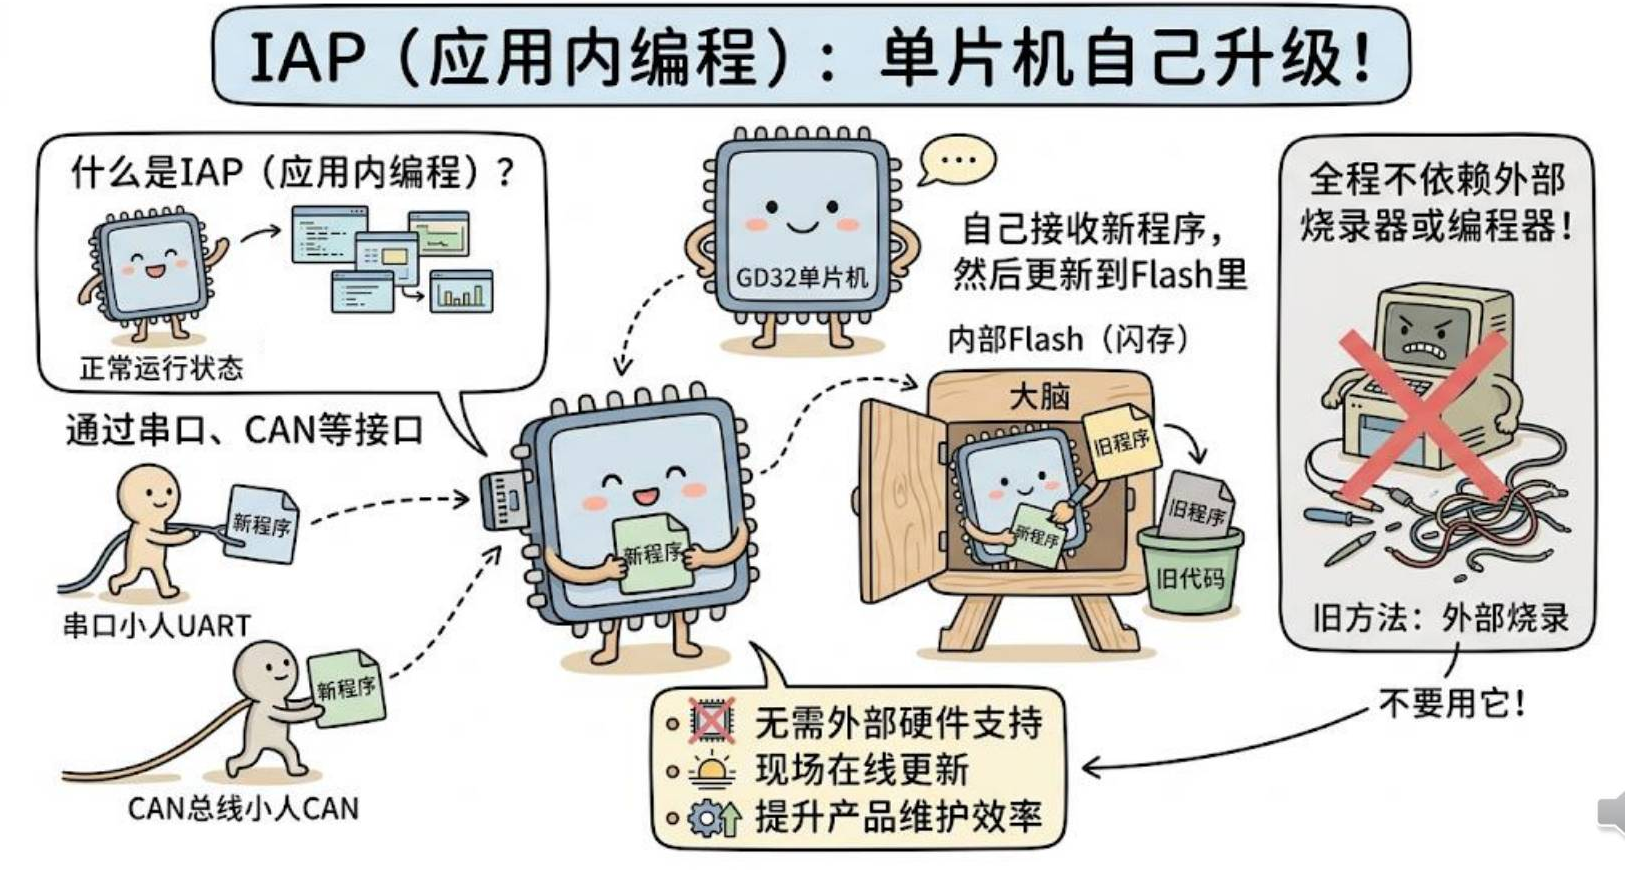

*讲义第 8 页：升级过程由设备中的软件完成，不必每次依赖外部烧录器写入新程序。*

**补充说明：**这里“不依赖外部烧录器”指已经具备 IAP 能力后的升级过程；设备首次仍需装入相应程序。“在线”也不表示 Flash 擦写时业务必然持续运行，或完全不需要复位。


## 4. OTA：通过无线通信传送固件

**OTA（Over-The-Air，空中下载／空中升级）**强调通过无线通信把固件传给设备。课程列举了蓝牙、Wi-Fi、4G／5G 等通道。

在本课单片机固件升级的语境下，可以把 OTA 理解为 **IAP 的无线实现**：固件通过无线链路送达设备，设备端仍然需要接收固件、更新 Flash，并使新程序运行起来。

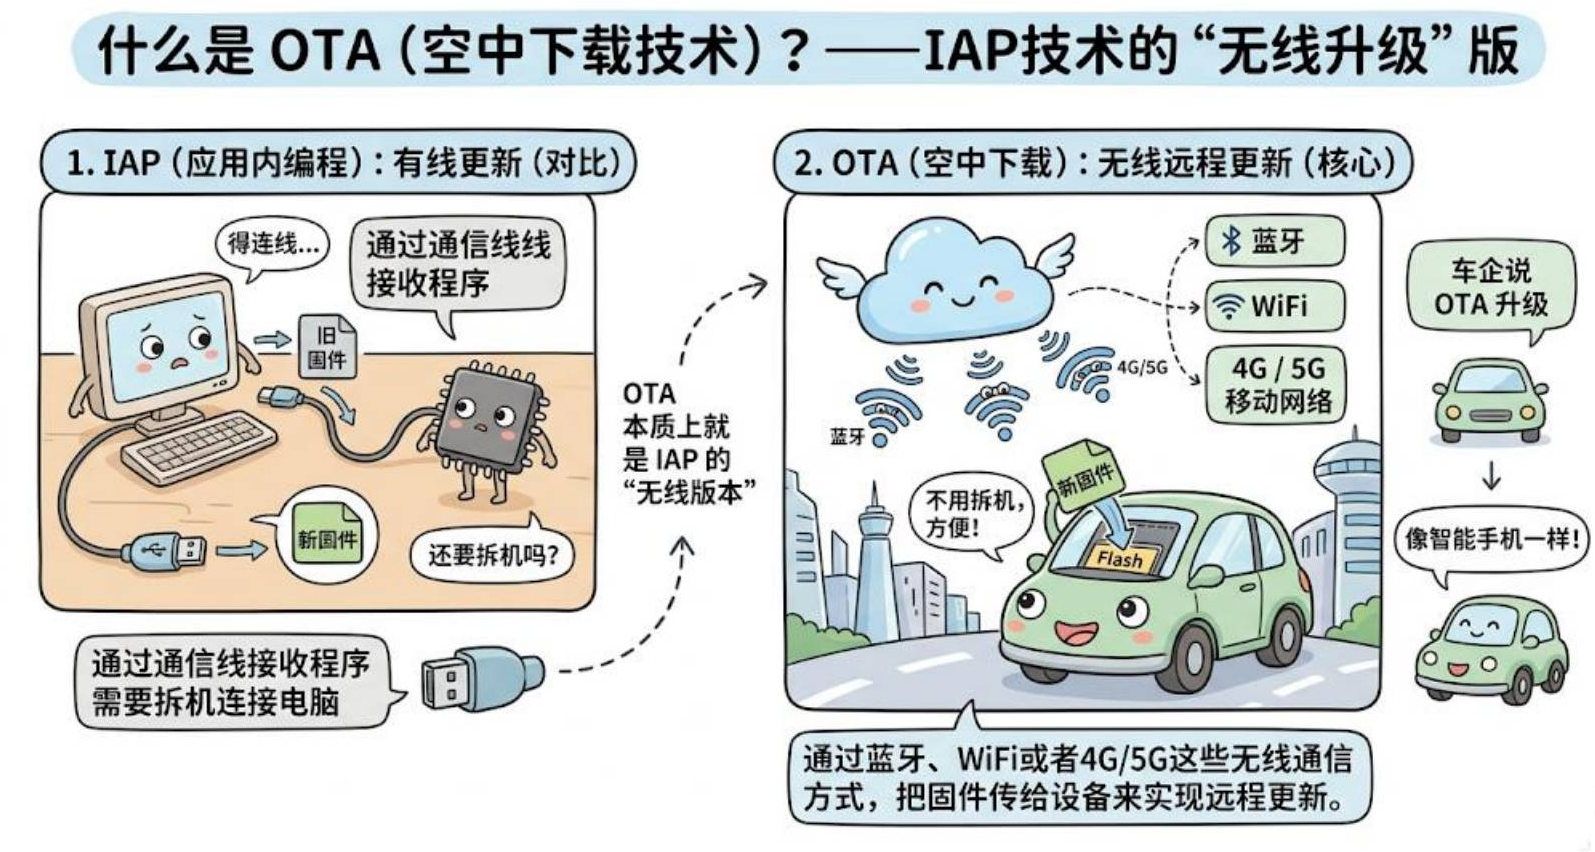

*讲义第 9 页用通信线与无线网络作对照。*

| 概念 | 本节关注的问题 | 课堂例子 |
|---|---|---|
| IAP | 设备能否用自身软件更新程序 | 通过 UART、CAN 接收固件，再更新 Flash |
| OTA | 固件是否经无线链路送达设备 | 通过蓝牙、Wi-Fi、4G／5G 接收固件 |

**补充说明：**图中把 IAP 标成“有线更新”，是为了对照教学中的有线示例；IAP 本身不限定只能使用有线通信。两者并不是互不相关的技术。


## 5. ISP 与 IAP：升级程序由谁提供、流程由谁控制

**ISP（In-System Programming，在系统编程）**与 IAP 容易混淆。老师在约 `03:37—04:20` 采用的区分方法，是看所依赖的 Bootloader 和进入升级模式的方式。

Bootloader 是启动引导程序。本课后续会由开发者编写自己的 Bootloader，负责升级流程和启动应用程序。

| 对比项 | 本课介绍的 ISP | 本课采用的 IAP 方案 |
|---|---|---|
| 所依赖的程序 | 芯片出厂自带的 Bootloader | 开发者编写的 Bootloader／升级程序 |
| 如何进入升级 | 配合特定 Boot 引脚等硬件条件 | 由软件设计升级触发条件和流程 |
| 升级流程的控制权 | 依照芯片厂家提供的方式 | 掌握在自己编写的软件中 |
| 灵活性 | 受厂家方案和进入条件约束 | 可按产品需要设计串口或网络等升级方式 |

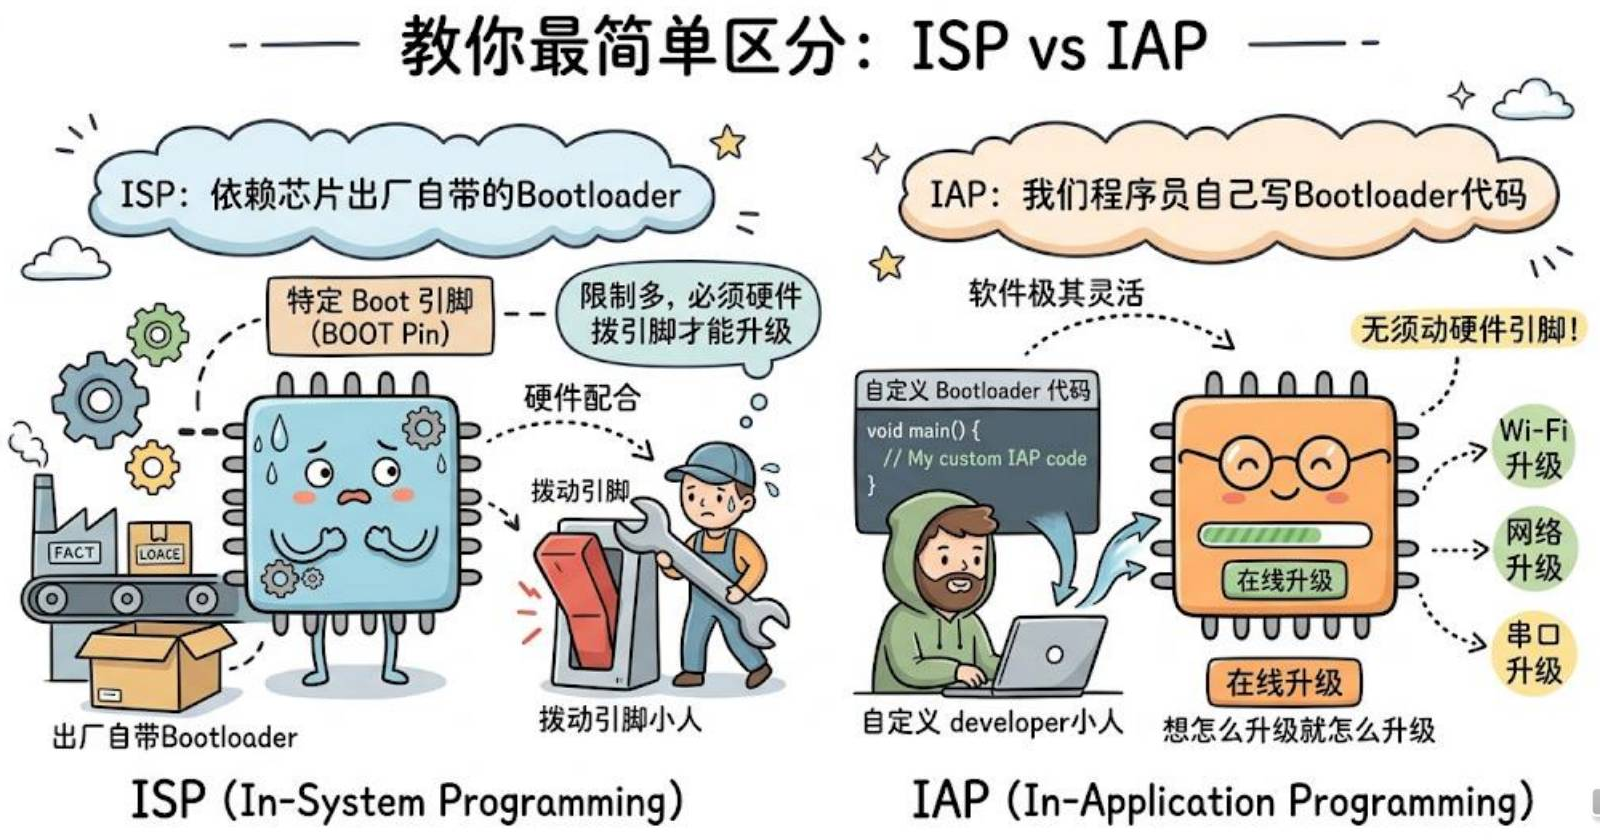

*讲义第 10 页。*

本节希望掌握的是：IAP 让开发者能够控制产品在什么条件下进入升级，以及如何完成升级。

**补充说明：**上表沿用本课 GD32 教学场景。不同芯片的 ISP 入口和功能可能不同，不能把“所有 ISP 都必须手动拨引脚”作为通用结论。


## 6. 升级设计还要考虑用户什么时候需要设备

视频约 `04:25—05:58` 引用了一个汽车升级的新闻案例：用户急需用车时，系统提示升级还需约 51 分钟，并且不能中途取消。这里按课堂引用记录，用于说明升级设计的问题，未另行核实该新闻。

老师借此强调，升级功能除了传输和写入程序，还要考虑用户使用设备的时机。软件设计应关注升级何时开始、升级期间设备能否使用、是否能暂停或恢复，以及怎样向用户说明当前状态，避免升级流程与紧急使用需求冲突。

远程更新的价值也因此不止是少插一次线：它能够支持批量维护、减少售后出差、持续增加功能，并让产品在交付后继续进行固件管理。

**补充说明：**“暂停／恢复”取决于升级阶段和存储方案，不能理解为正在擦写程序时也能任意断电或取消。本节提出设计目标，尚未实现相应机制。


## 7. 常见应用与学习这项技术的原因

视频约 `06:05—07:03` 用四类设备说明 IAP／OTA 的实际用途。

| 应用场景 | 课程中的更新需求 | 解决的维护困难 |
|---|---|---|
| 新能源汽车 | 通过 OTA 补丁更新或增加功能，例如自动泊车相关功能 | 功能迭代不必每次回到现场重新烧录 |
| 智能电表 | 由主站下发更新，修改统计等算法 | 避免逐户拆表更新 |
| 工业控制设备 | 为高温、高压等危险区域的设备更新程序、打补丁 | 预留通信接口后，可在安全区维护 |
| 智能穿戴设备 | 通过手机同步，修复手表计步等问题 | 用户无需拆开设备连接烧录器 |

这些例子的共同点是：硬件仍可继续使用，需要调整的是运行在硬件上的程序。具体采用有线还是无线通信，由设备的通信条件决定。

随后，课程归纳了三类需求：

1. **产品持续迭代。** 产品交付后还会修复问题和增加软件功能，需要方便地推送新版本。
2. **物联网设备规模扩大。** 当设备达到十万、百万量级，逐台现场维护难以支撑。
3. **降低维护成本。** 能通过远程软件更新完成的工作，可以减少售后工程师反复到现场操作。

因此，固件管理需要覆盖设备的使用生命周期，而不只关注开发阶段能否把程序烧进去。


## 8. 课程学习路径：从存储和通信到完整升级

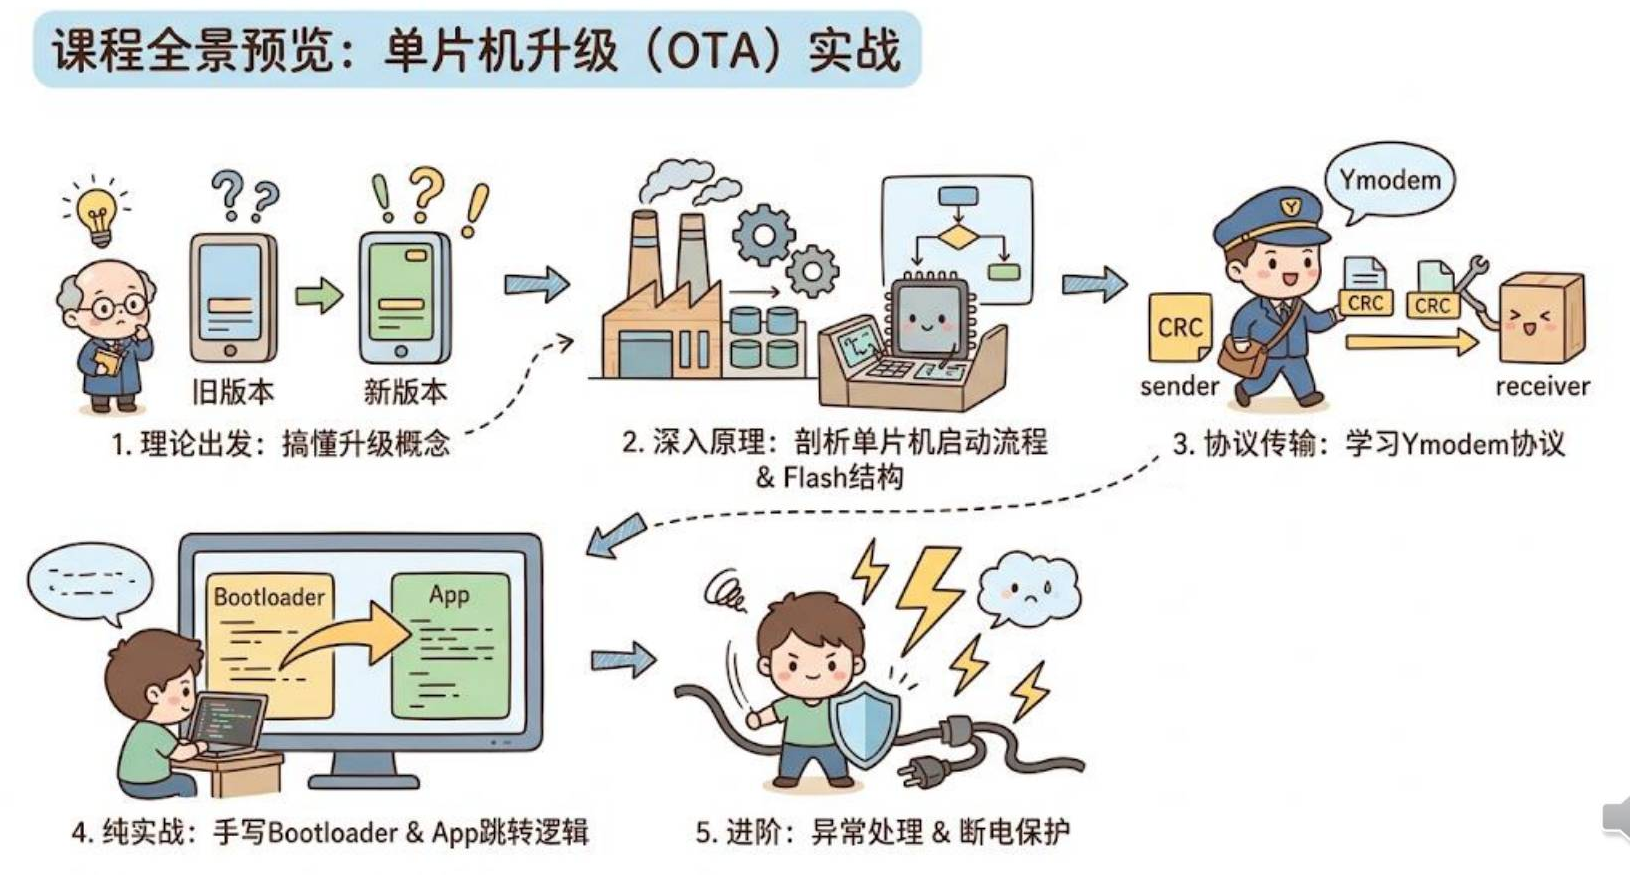

*讲义第 18 页，对应视频约 `08:13—09:11`。*

| 学习阶段 | 要弄清的问题 |
|---|---|
| 升级概念 | 什么是 IAP、OTA，为什么设备需要在线更新 |
| 单片机启动和 Flash 结构 | 程序保存在哪里，单片机如何启动，Flash 如何读写 |
| Ymodem 协议 | 发送端与接收端如何配合传输固件文件 |
| Bootloader 与 App | 怎样编写升级程序，以及如何跳转到应用程序 |
| 异常与断电保护 | 升级过程出现异常或掉电时，如何处理 |

App 在这里指设备上的应用程序，即实现产品业务功能的固件。学习顺序先解决存储和通信问题，再组合成能够更新并启动应用程序的流程。原课开头还提到，会把前面的知识串起来完成串口升级案例。

本节的全景图用于说明后续要做什么，尚未给出分区地址、协议报文、跳转代码或断电恢复实现。


## 9. 实操前的硬件与软件准备

讲义第 19 页和视频约 `09:13—09:58` 说明了实验环境。先准备能够正常编译、烧录并运行的标准库基础工程，再在此基础上学习升级功能。

| 类别 | 准备项 | 用途与课堂说明 |
|---|---|---|
| 开发板 | GD32 开发板，推荐 F303 或 F407 系列 | Flash 空间较大，便于后续实验；老师演示使用 GD32F407 |
| 通信工具 | USB 转串口模块 | 作为串口通信桥梁，后续用于传固件；老师使用的下载器自带串口功能 |
| 下载工具 | 能给开发板烧录基础工程的下载器 | 本节先完成普通工程的编译、烧录和验证 |
| 编译环境 | Keil MDK | 课程以 Keil 为主；讲义也提到 IAR 可用 |
| 串口调试工具 | `XCOM.exe` | 本节用于打开串口、观察启动日志，视频从配套 `Resource` 资源中打开 |
| 串口终端 | SecureCRT 或 Xshell 等 | 后续通过 Serial 串口和 Ymodem 发送固件文件 |

本节 XCOM 的用途是观察串口输出；后续选择终端软件时，还需要它具备课程所用的 Ymodem 文件发送能力。


## 10. 视频实操：运行 LED 与串口基础工程

### 10.1 先建立后续实验的基础

视频约 `09:58—10:46` 给开发板通电，并在 Keil 中打开示例工程。目标是先证明普通应用程序能正常运行：PB2 上的 LED 周期闪烁，串口在程序启动时输出日志。

操作对象是示例工程的 `main.c`。下面按视频可见代码整理，省略了截图中的分步注释；工程头文件、串口实现和延时函数定义仍由原示例提供，这不是一个独立完整工程。

### 10.2 配置 PB2 为输出

```c
static void GPIO_config(rcu_periph_enum rcu, uint32_t port, uint32_t pin) {
    rcu_periph_clock_enable(rcu);
    gpio_mode_set(port, GPIO_MODE_OUTPUT, GPIO_PUPD_NONE, pin);
    gpio_output_options_set(port, GPIO_OTYPE_PP, GPIO_OSPEED_MAX, pin);
    gpio_bit_write(port, pin, RESET);
}
```

这段函数先使能对应 GPIO 外设时钟，然后配置输出模式、无上下拉、推挽输出及输出速度，最后把初始输出设为低电平。`RESET` 在这里表示写低电平，不是复位整个单片机。

在 `main()` 中传入 `RCU_GPIOB`、`GPIOB`、`GPIO_PIN_2`，即初始化 GPIOB 的第 2 号引脚 PB2。

### 10.3 初始化后打印日志，并循环翻转 LED

```c
int main(void) {
    nvic_priority_group_set(NVIC_PRIGROUP_PRE2_SUB2);
    systick_config();
    DelayInit();
    USART_init();
    GPIO_config(RCU_GPIOB, GPIOB, GPIO_PIN_2);

    printf("Hello World!\n");

    while (1) {
        gpio_bit_toggle(GPIOB, GPIO_PIN_2);
        DelayNms(500);
    }
}
```

代码先设置中断优先级分组，初始化系统滴答定时器、延时模块、串口和 GPIO，再打印 `Hello World!`。循环中翻转 PB2 的电平，每次翻转后延时 500 ms；课堂观察到绿色 LED 亮约 500 ms、灭约 500 ms，即完整亮灭周期约为 1 秒。

`DelayInit()`、`DelayNms()` 和 `USART_init()` 是视频示例中的函数名，应配合示例工程使用。启动日志位于循环外，因此每次复位启动时打印一次，不是随 LED 每隔 500 ms 重复打印。

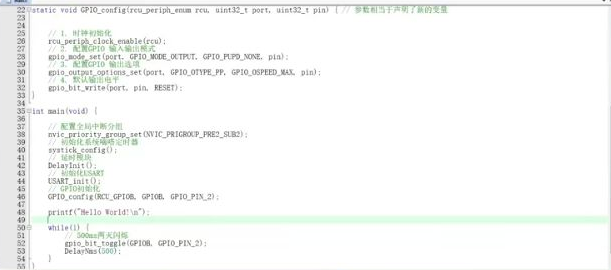

*视频实操代码画面裁切。与讲义只列出“环境准备”相比，视频还展示了具体的 GPIO 配置和主循环。*


## 11. 编译、烧录与课堂验证

视频约 `10:47—11:43` 的操作顺序如下：

1. 打开配套 `Resource` 中的 `XCOM.exe`。
2. 选择开发板对应的串口设备并打开串口。串口号以自己电脑识别到的设备为准，通信参数应与示例工程中的 USART 配置一致。
3. 在 Keil 中编译示例工程，然后把程序烧录到开发板。
4. 复位开发板，观察串口接收区，确认出现启动日志 `Hello World!`。
5. 观察开发板上的绿色 LED，确认按亮 500 ms、灭 500 ms 的节奏运行。
6. 保留这个已经验证的基础工程，作为后续实验的起点。

| 验证项 | 课堂观察到的现象 | 对应的代码或操作 |
|---|---|---|
| 基础工程可构建并下载 | 工程完成编译和烧录 | Keil 编译、下载 |
| 程序启动并进入初始化流程 | 复位后接收到 `Hello World!` | `USART_init()` 之后的 `printf()` |
| GPIO 和延时主循环运行 | 绿色 LED 亮灭各约 500 ms | `gpio_bit_toggle()` 与 `DelayNms(500)` |

**这一步验证的是基础应用工程。** 本节尚未通过串口发送固件，也未执行 IAP／OTA 更新。先有一个运行结果明确的普通工程，后续学习 Flash、传输协议和启动跳转时才有可对照的基础。


## 12. 本课重点

本节最后归纳了四点：

- **一句话概括：**IAP 让设备通过自身的软件更新程序；本课的 OTA 是经无线通信完成这种更新。
- **核心价值：**远程维护、减少维护成本、支持产品持续迭代。
- **重点区别：**区分 ISP 与 IAP 所依赖的 Bootloader，把升级流程的控制权掌握在自己编写的软件中。
- **思维转变：**从开发时“接上下载器把程序烧进去”，进一步考虑设备交付后如何通过通信、升级软件和 Flash 操作完成在线更新。

容易混淆的是，把 IAP 和 OTA 当成完全不相干的技术，或认为固件已经收到就等于升级已经完成。后续仍需学习如何写入程序、启动新应用以及处理异常。

本节已经准备并验证了 LED／串口模板工程。下一步进入 GD32 的 Flash 结构与读写实战，解决设备如何保存和更新程序的问题。
